In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
from imports import *

# Harvard sessions: timing and design checks, then compile

Harvard ran each session as one or more short **practice** blocks (100% coherence, no prior) followed by about four
**trial** blocks of 160 trials (80 green, 80 red), for 600+ trials in total. Every block is its own file under
`raw/harvard_data/{pd,hc}/<session>/`:

- `practice/YYMMDD_HHMMSS.mat`
- `trial/YYMMDD_HHMMSS.mat`, or a `.mat` directly inside the session folder (also read as a trial block)

Anything else (a subfolder inside `trial/`, say) is reported and left out.

This notebook works from the raw block files only, with the checks shared by all block-recorded sites
(`src/utils/blocks.py`):

1. **Timing.** Three clocks are compared (below). A block whose timestamps disagree was not recorded in that session.
2. **Design.** The per-colour target split, and the prior it implies. Every trial block in a session should show the same prior.
3. **Order.** Practice finished before the first trial block started, and trial blocks follow one another without overlapping.

It writes, to `compiled/harvard/`:

| file | contents |
|---|---|
| `blocks.csv` | one row per raw file: timestamps, checks, design, `use` and `excluded_reason` |
| `session_summary.csv` | one row per session: block counts, prior consistency, order checks, `issues`, `notes` |
| `sessions/<session>.parquet` | the session's trials from the blocks with `use`, practice then trial, in time order |

Nothing is screened for accuracy or design here. Sessions with an inconsistent prior or a partial block are compiled
and flagged, so the decision about them can be made, and changed, downstream.

### Three clocks per block

- **Filename** (`YYMMDD_HHMMSS`): when the task program started the block. The first trial can follow some minutes later.
- **MAT header** (`Created on: ...`, written by MATLAB's `save`): when the block was saved, about 15 s after its last trial.
- **`time` matrix**: event times in milliseconds on the PC's monotonic clock. It runs on through a whole session, so
  the offset *header time − last clock value* is the same for every block recorded on that machine that day. It steps
  up when the PC sleeps between blocks and down when the wall clock is corrected; such same-day shifts are kept.

Hence, for a genuine block:

- header − filename ≥ recorded duration (last − first clock value), give or take a clock correction;
- its header offset matches the session's (the median over the session's trial blocks), or shifts from it on the same day.

Filesystem modification times are not used: they record when files were copied, not when they were recorded.

In [2]:
import re

from src.data_io import catalog
from src.utils import blocks as blk

GROUPS = {"pd": catalog.path("raw_harvard_sessions", subject_type="pd"), "hc": catalog.path("raw_harvard_sessions", subject_type="hc")}
HARVARD = GROUPS["pd"].parent


def natural_key(folder):
    """P25_off before P25_on before P26_off; HC2 before HC10."""
    number = re.search(r"\d+", folder.name)
    return (int(number.group()) if number else 0, folder.name)


def block_phase(file, folder):
    parts = file.relative_to(folder).parts
    if len(parts) == 1:
        return "trial"  # directly inside the session folder
    if len(parts) == 2 and parts[0] in ("practice", "trial"):
        return parts[0]
    return "unexpected"

## 1. Inventory: every `.mat` file under each session folder

In [3]:
listing = []
for group, group_dir in GROUPS.items():
    for folder in sorted((f for f in group_dir.iterdir() if f.is_dir()), key=natural_key):
        subject_id, _, medication = folder.name.partition("_")
        for file in sorted(folder.rglob("*.mat")):
            listing.append({"session_id": folder.name, "subject_id": subject_id.upper(), "group": group,
                            "medication": medication.lower() or None, "phase": block_phase(file, folder),
                            "file": f"{folder.name}/{file.relative_to(folder).as_posix()}",
                            "path": file.relative_to(HARVARD).as_posix()})
blocks, decoded = blk.read_blocks(pd.DataFrame(listing, columns=blk.LISTING_COLUMNS), HARVARD)
print(f"{len(blocks)} files in {blocks.session_id.nunique()} sessions "
      f"({blocks[blocks.group == 'pd'].subject_id.nunique()} patients, {blocks[blocks.group == 'hc'].subject_id.nunique()} controls)")
blocks.pivot_table(index="session_id", columns="phase", values="file", aggfunc="size", sort=False).fillna(0).astype(int).T

192 files in 35 sessions (10 patients, 15 controls)


session_id,P25_off,P25_on,P26_off,P26_on,P27_off,P27_on,P28_off,P28_on,P29_off,P29_on,P30_off,P30_on,P31_off,P31_on,P32_off,P32_on,P33_off,P33_on,P34_off,P34_on,HC1,HC2,HC3,HC5,HC6,HC7,HC8,HC9,HC10,HC11,HC12,HC13,HC14,HC15,HC16
phase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
practice,1,0,1,0,0,1,1,2,1,2,1,2,1,2,1,1,1,2,1,1,3,2,1,3,1,2,2,1,1,2,1,2,1,1,5
trial,4,4,4,4,4,4,5,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,5,4,4,4,4,4,4,4,4,4


## 2. Timing checks

In [4]:
blk.check_timing(blocks)
timing_ok = blocks.header_same_day & blocks.saved_after_recording & (blocks.clock_status == "on clock")
print(f"{timing_ok.sum()} of {len(blocks)} files pass all timing checks. The others:")
blocks.loc[~timing_ok, ["file", "filename_time", "header_time", "n_rows", "duration_s", "wait_s", "clock_drift_s", "clock_status", "duplicate_of"]].round(0)

192 of 192 files pass all timing checks. The others:


,file,filename_time,header_time,n_rows,duration_s,wait_s,clock_drift_s,clock_status,duplicate_of


Among the files that pass, the wait between program start and save beyond the recorded trials, and the clock drift:

In [5]:
blocks.loc[timing_ok, ["wait_s", "clock_drift_s"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
wait_s,192.0,48.0,87.2,-1.9,15.8,18.5,35.1,861.4
clock_drift_s,192.0,0.1,1.9,-10.3,-0.2,0.0,0.2,11.0


## 3. Which files are used

A file is left out, for the first reason that applies, when it

1. sits outside `practice/` and `trial/` (and is not directly in the session folder);
2. is an aborted start (not a 10-column event matrix, or under 10 rows);
3. was not recorded in this session: off the session's clock, or saved before its own trials could have ended;
4. repeats the contents of an earlier used file of the same session.

In [6]:
blk.mark_use(blocks)
print(f"using {blocks.use.sum()} of {len(blocks)} files; left out:")
blocks.loc[~blocks.use, ["file", "header_time", "n_rows", "excluded_reason", "duplicate_of"]]

using 190 of 192 files; left out:


,file,header_time,n_rows,excluded_reason,duplicate_of
121,HC5/practice/250219_124333.mat,2025-02-19 12:45:13,4,aborted (4 x 9 event matrix),None
136,HC7/trial/250228_094106.mat,2025-02-28 09:41:27,1,aborted (1 x 7 event matrix),None


### Where the left-out files were recorded

`recorded_with` names the sessions run **the same day** whose used blocks share the file's clock (the clock survives
overnight when the PC is not restarted, so other days are not evidence). Files that share a day and an offset form one
`recording_run`; `copies_of` is the used file with identical contents.

In [7]:
runs = blk.add_provenance(blocks)
runs

,saved_from,saved_to,n_files,recorded_with,filed_under,reasons,copies_of
recording_run,,,,,,,
1.0,2025-02-19 12:45:13,2025-02-19 12:45:13,1,HC5,HC5,aborted,
2.0,2025-02-28 09:41:27,2025-02-28 09:41:27,1,HC7,HC7,aborted,


**Removed from raw on 2026-10-19.** These checks flagged 15 practice files in P25–P27 (OFF and ON) that were not
recorded in their sessions: three byte-identical copies (of HC7's and HC11's practice, and of P27 ON's own
`250314_121934`) and twelve recorded on 2025-04-28, 13–45 days after the dates in their names, then renamed into the
folders on 2025-04-29. They and HC16's duplicate folder `trial/h16_pract_2 last ones/` were removed; copies remain in
`raw_backup_20261019/harvard_data/`. The details are in `docs/data-screening.md` (Harvard run-level investigation).
Since then P25 ON, P26 ON and P27 OFF have empty `practice/` folders, and only the two aborted stubs are left out here.

## 4. Design of each block

For every 10-column block: the share of each colour's targets on the right, the prior that implies (a colour with
more than 60% to one side carries it: `gr` green-right, `rl` red-left, ...; `none` if neither does), and the design
error used by the load-time screen (`src.utils.sessions.prior_design_error`: the larger departure from 75:25 for the
prior colour and 50:50 for the other). Practice blocks should show only 100% coherence and no prior.

In [8]:
blk.add_design(blocks, decoded)
practice = blocks[blocks.use & (blocks.phase == "practice")]
odd_practice = practice[(practice.coherences != "100") | (practice.block_prior != "none")]
print(f"{len(practice)} used practice blocks; {len(odd_practice)} with coherences other than 100% or a prior")
display(odd_practice[["file", "n_shown", "coherences", "green_right_pct", "red_right_pct", "block_prior"]])

trial_blocks = blocks[blocks.use & (blocks.phase == "trial")]
print(f"{len(trial_blocks)} used trial blocks, {trial_blocks.partial.sum()} partial:")
trial_blocks.loc[trial_blocks.partial, ["file", "n_rows", "n_shown", "green_right_pct", "red_right_pct", "block_prior"]].round(1)

49 used practice blocks; 0 with coherences other than 100% or a prior


,file,n_shown,coherences,green_right_pct,red_right_pct,block_prior


141 used trial blocks, 1 partial:


,file,n_rows,n_shown,green_right_pct,red_right_pct,block_prior
30,P28_off/trial/250520_080718.mat,55,55.0,78.6,25.9,gr+rl


## 5. Session checks

Over each session's used blocks:

- **prior consistent**: every trial block implies the same prior; `session_prior` is the one most blocks show;
- **design ok**: every complete trial block is within the design tolerance of 75:25 / 50:50 (a session run with both
  colours biased is consistent but not ok);
- **practice before trial**: the last practice block was saved before the first trial block started, by the
  filename/header times and by the session clock;
- **block order**: blocks are in the same order by filename, header and clock, and no trial block starts before the
  previous one was saved;
- **one day** and **600+ trials**.

In [9]:
summary = blk.session_summary(blocks)
show = ["session_id", "date", "n_practice_blocks", "n_trial_blocks", "n_shown", "block_priors", "session_prior",
        "prior_consistent", "design_ok", "practice_before_trial", "practice_to_trial_min", "block_order_consistent", "issues"]
summary[show].round(1)

,session_id,date,n_practice_blocks,n_trial_blocks,n_shown,block_priors,session_prior,prior_consistent,design_ok,practice_before_trial,practice_to_trial_min,block_order_consistent,issues
0,P25_off,2025-03-18,1,4,640,rl | rl | rl | rl,rl,True,True,True,1.4,True,
1,P25_on,2025-03-25,0,4,640,rr | rr | rr | rr,rr,True,True,False,NaN,True,no practice recorded in this session
2,P26_off,2025-04-01,1,4,640,gl | gl | gl | gl,gl,True,True,True,1.2,True,
3,P26_on,2025-04-15,0,4,640,gr | gr | gr | gr,gr,True,True,False,NaN,True,no practice recorded in this session
4,P27_off,2025-03-25,0,4,640,rl | rl | rl | rl,rl,True,True,False,NaN,True,no practice recorded in this session
5,P27_on,2025-03-14,1,4,640,gl | gl | gl | gl,gl,True,True,True,1.3,True,
6,P28_off,2025-05-20,1,5,695,gr+rl | gr+rl | gr+rl* | gr+rl | gr+rl,gr+rl,True,False,True,1.6,True,design off 75:25 / 50:50 (error 0.25); 1 parti...
7,P28_on,2025-06-06,2,4,640,gl | gl | gl | gl,gl,True,True,True,1.4,True,
8,P29_off,2025-05-21,1,4,642,gr+rl | gr+rl | gr+rl | gr+rl,gr+rl,True,False,True,1.6,True,design off 75:25 / 50:50 (error 0.25)
9,P29_on,2025-05-07,2,4,640,gl | gl | gl | gl,gl,True,True,True,1.8,True,


Sessions with something to look at (`*` marks a partial block):

In [10]:
summary.loc[(summary.issues != "") | (summary.notes != ""), ["session_id", "block_priors", "issues", "notes"]].style.hide(axis="index")

session_id,block_priors,issues,notes
P25_on,rr | rr | rr | rr,no practice recorded in this session,
P26_on,gr | gr | gr | gr,no practice recorded in this session,
P27_off,rl | rl | rl | rl,no practice recorded in this session,
P28_off,gr+rl | gr+rl | gr+rl* | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25); 1 partial block(s),
P29_off,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25),
P30_on,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25),
P32_on,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25),
P33_off,gr+rl | gr | gr | gr,block priors differ (gr+rl | gr | gr | gr); design off 75:25 / 50:50 (error 0.25),
P33_on,gr+rl | gr+rl | gr+rl | gr+rl,design off 75:25 / 50:50 (error 0.25),
HC5,gr | gr | gr | gr,1 file(s) left out,


## 6. Timeline

Each used block at its wall-clock time, in minutes from the start of the first trial block. Practice should sit left
of zero. Trial blocks carry their implied prior; hatched blocks are partial. Files left out are not drawn.

saved session_timeline.pdf, session_timeline.png


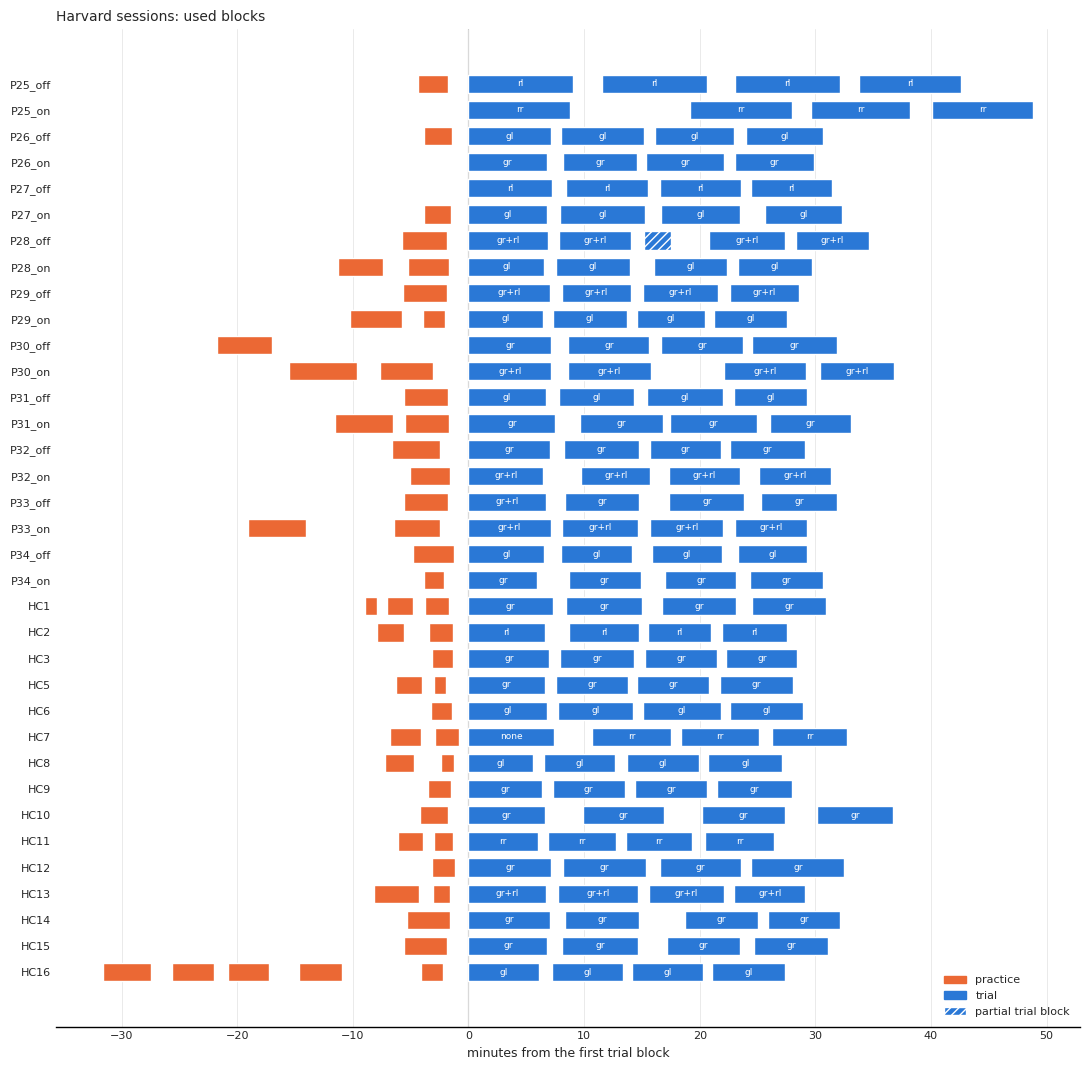

In [11]:
fig = blk.plot_timeline(blocks, summary, "Harvard sessions: used blocks")
catalog.save_figure(fig, "harvard/session_timeline")
plt.show()

## 7. Findings

The results above, written out from the tables (nothing here is typed by hand).

In [12]:
print("\n".join(f"- {line}" for line in blk.findings(blocks, summary, runs)))

- 192 files in 35 sessions; 190 used, 2 left out (2 aborted).
- 1 left-out file(s) (aborted) saved 2025-02-19 12:45, on the clock of HC5, filed under HC5.
- 1 left-out file(s) (aborted) saved 2025-02-28 09:41, on the clock of HC7, filed under HC7.
- Sessions without trial blocks: none.
- No practice recorded in-session: P25_on, P26_on, P27_off.
- Practice not finished before the first trial block: none.
- Blocks out of order or trial blocks overlapping: none.
- Blocks on more than one day: none.
- Clock shifts within a session (sleep or clock correction; blocks kept): none.
- Block priors differ within the session: P33_off (gr+rl | gr | gr | gr); HC7 (none | rr | rr | rr).
- Design off 75:25 / 50:50 in a complete block: P28_off (gr+rl); P29_off (gr+rl); P30_on (gr+rl); P32_on (gr+rl); P33_off (gr); P33_on (gr+rl); HC7 (rr); HC13 (gr+rl).
- Partial trial blocks: P28_off/trial/250520_080718.mat (55 trials).
- Under 600 trials: none; range 640-695, median 640.


## 8. Compile

Each session's used blocks, practice then trial, each in time order, as one trial table with the shared session
columns plus the block it came from. `prior` is the session's prior (`session_prior`); `prior_color` and
`prior_direction` are filled only when it is a single colour.

In [13]:
blk.compile_sessions(blocks, decoded, summary, "compiled_harvard_session")
catalog.save(blocks.drop(columns=blk.INTERNAL_COLUMNS), "compiled_harvard_blocks")
catalog.save(summary, "compiled_harvard_session_summary")

saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P25_off.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P25_on.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P26_off.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P26_on.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P27_off.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P27_on.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P28_off.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P28_on.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P29_off.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/P29_on.parquet


...

saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC9.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC10.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC11.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC12.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC13.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC14.parquet
saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC15.parquet


saved compiled_harvard_session -> /mnt/pd-data/compiled/harvard/sessions/HC16.parquet
saved compiled_harvard_blocks -> /mnt/pd-data/compiled/harvard/blocks.csv
saved compiled_harvard_session_summary -> /mnt/pd-data/compiled/harvard/session_summary.csv


## 9. Selecting blocks later

Every compiled trial carries its block's prior, whether the block ran the intended design (`block_design_ok`) and
whether it implies the session's prior (`block_matches_session_prior`). `catalog.load_block_sessions` reads the
compiled sessions and `src.utils.blocks.select_blocks` picks blocks. For the two sessions whose blocks differ:

In [14]:
from src.utils.blocks import select_blocks

mixed = catalog.load_block_sessions(["harvard"], ["P33_off", "HC7"])
display(mixed[mixed.phase == "trial"].groupby(["session_id", "block"]).agg(
    block_prior=("block_prior", "first"), trials=("block", "size"), design_ok=("block_design_ok", "first"),
    matches_session_prior=("block_matches_session_prior", "first")))
correct = select_blocks(mixed, design_ok=True)  # P33 OFF blocks 2-4 (gr), HC7 blocks 2-4 (rr)
odd = select_blocks(mixed, design_ok=False, relabel=True)  # the first block of each, under its own prior
print({"correct blocks": correct.groupby("session_id").block.unique().to_dict(), "other blocks": odd.groupby("session_id").prior.unique().to_dict()})

block_prior  trials  design_ok  matches_session_prior
session_id block                                                      
HC7        1            none     165      False                  False
           2              rr     164       True                   True
           3              rr     160       True                   True
           4              rr     161       True                   True
P33_off    1           gr+rl     160      False                  False
           2              gr     160       True                   True
           3              gr     160       True                   True
           4              gr     160       True                   True

{'correct blocks': {'HC7': array([2, 3, 4]), 'P33_off': array([2, 3, 4])}, 'other blocks': {'HC7': array(['none'], dtype=object), 'P33_off': array(['gr+rl'], dtype=object)}}
